<a href="https://colab.research.google.com/github/Madz2681/beginning-bioinformatics/blob/main/Module_11_scRNA_Seq_B_cell_classifer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q "pandas==2.2.3" "scanpy[leiden]" "pynndescent==0.6.0"

In [ ]:
# Core scverse libraries
from __future__ import annotations

import anndata as ad

# Data retrieval
import pooch
import scanpy as sc

In [ ]:
sc.settings.set_figure_params(dpi=50, facecolor="white")

/tmp/ipykernel_663/2889020069.py:1: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=50, facecolor="white")


In [ ]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("scverse_tutorials"),
    base_url="doi:10.6084/m9.figshare.22716739.v1/",
)
EXAMPLE_DATA.load_registry_from_doi()

In [ ]:
samples = {
    "s1d1": "s1d1_filtered_feature_bc_matrix.h5",
    "s1d3": "s1d3_filtered_feature_bc_matrix.h5",
}
adatas = {}

for sample_id, filename in samples.items():
    path = EXAMPLE_DATA.fetch(filename)
    sample_adata = sc.read_10x_h5(path)
    sample_adata.var_names_make_unique()
    adatas[sample_id] = sample_adata

adata = ad.concat(adatas, label="sample")
adata.obs_names_make_unique()
print(adata.obs["sample"].value_counts())
adata

/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


sample
s1d1    8785
s1d3    8340
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 17125 × 36601
    obs: 'sample'

# **Quality Control**

In [ ]:
# mitochondrial genes, "MT-" for human, "Mt-" for mouse
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

In [ ]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)

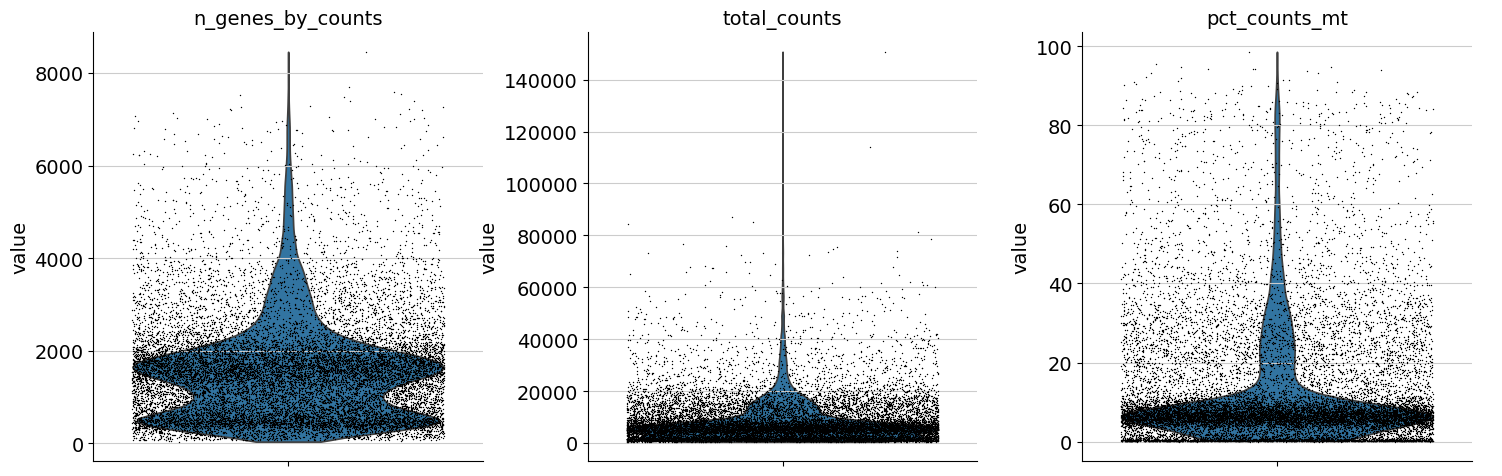

In [ ]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

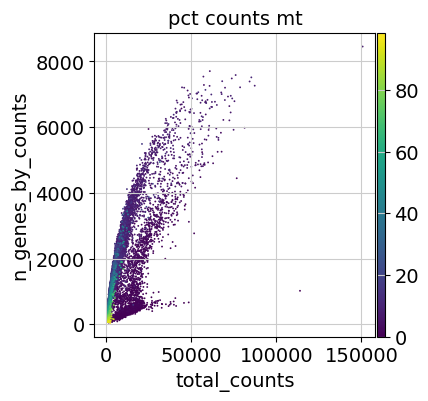

In [ ]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

In [ ]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)

## **Doublet Detection**

In [ ]:
sc.pp.scrublet(adata, batch_key="sample")

# **Normalization**

In [ ]:
# Saving count data
adata.layers["counts"] = adata.X.copy()

In [ ]:
# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)

# **Feature Selection**

In [ ]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample")

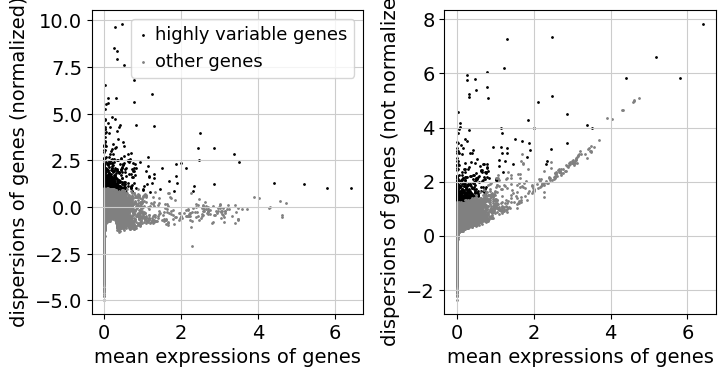

In [ ]:
sc.pl.highly_variable_genes(adata)

# **Dimensionality Reduction**

In [ ]:
sc.tl.pca(adata)

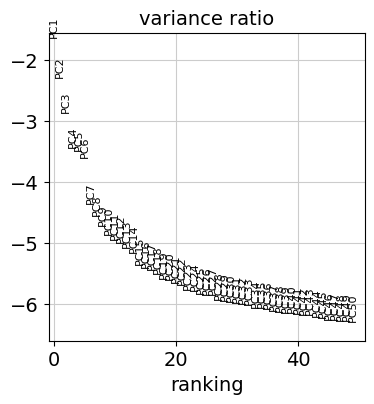

In [ ]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

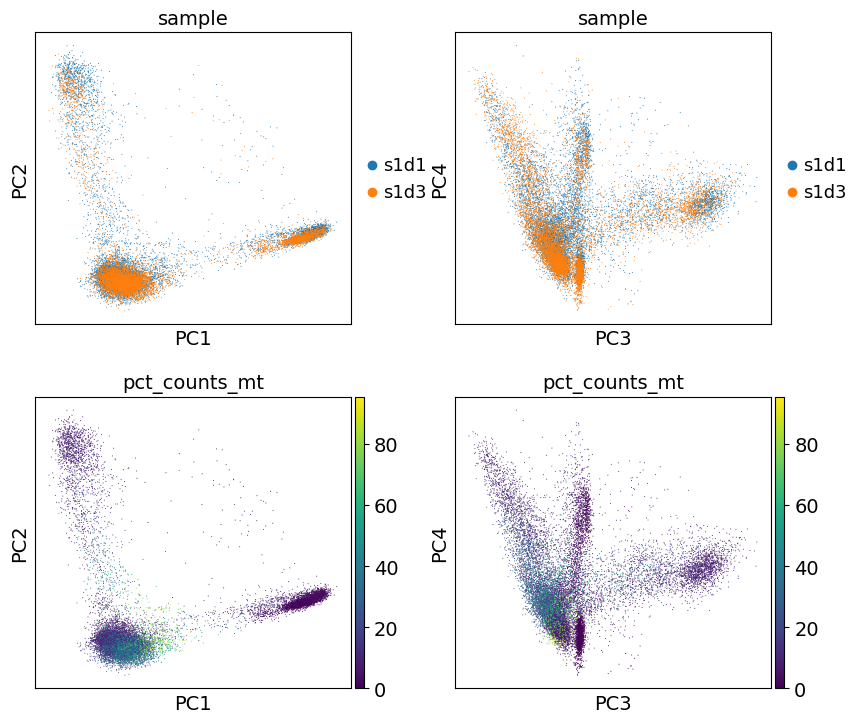

In [ ]:
sc.pl.pca(
    adata,
    color=["sample", "sample", "pct_counts_mt", "pct_counts_mt"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)

# **Nearest Neighbor graph Construction and Visualization**

In [ ]:
sc.pp.neighbors(adata)

In [ ]:
sc.tl.umap(adata)

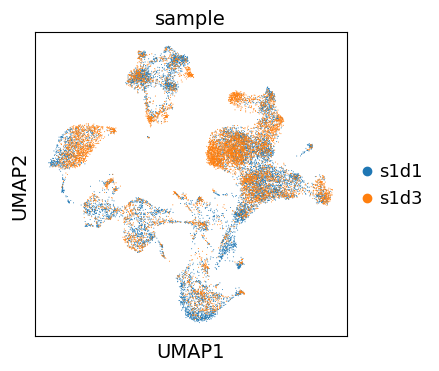

In [ ]:
sc.pl.umap(
    adata,
    color="sample",
    # Setting a smaller point size to get prevent overlap
    size=2,
)

# **Clustering**

In [ ]:
# Using the igraph implementation and a fixed number of iterations can be significantly faster,
# especially for larger datasets
sc.tl.leiden(adata, flavor="igraph", n_iterations=2)

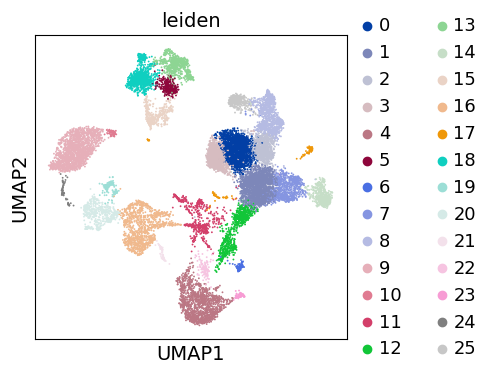

In [ ]:
sc.pl.umap(adata, color=["leiden"])

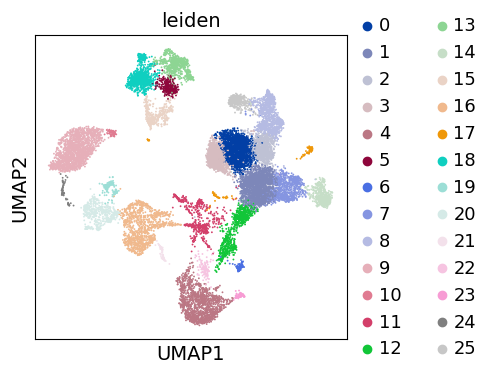

In [ ]:
ax = sc.pl.umap(adata, color=["leiden"], show=False)
ax.figure.savefig("output_path.png", bbox_inches="tight")

# **Re-assess Qaulity Control**

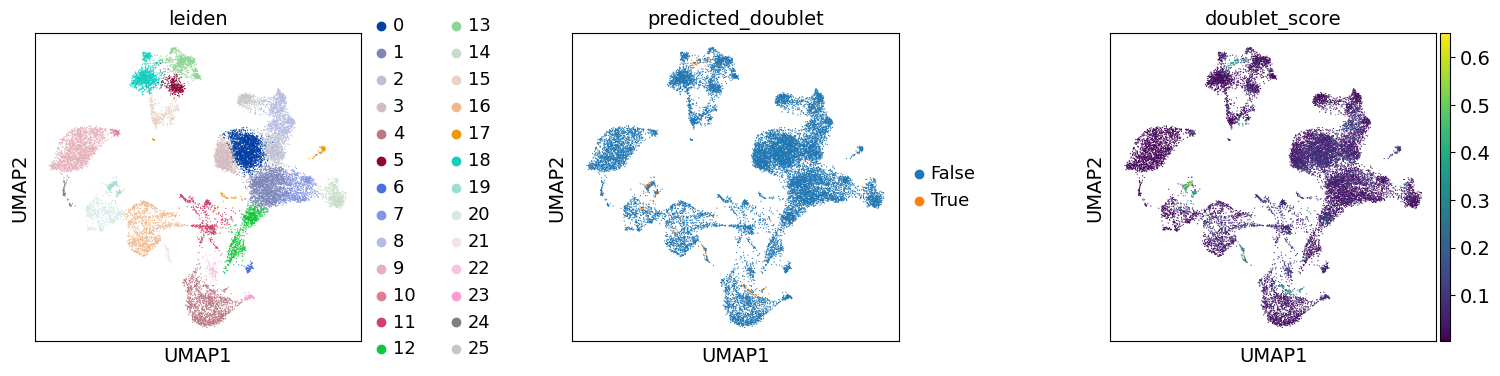

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    # increase horizontal space between panels
    wspace=0.5,
    size=3,
)

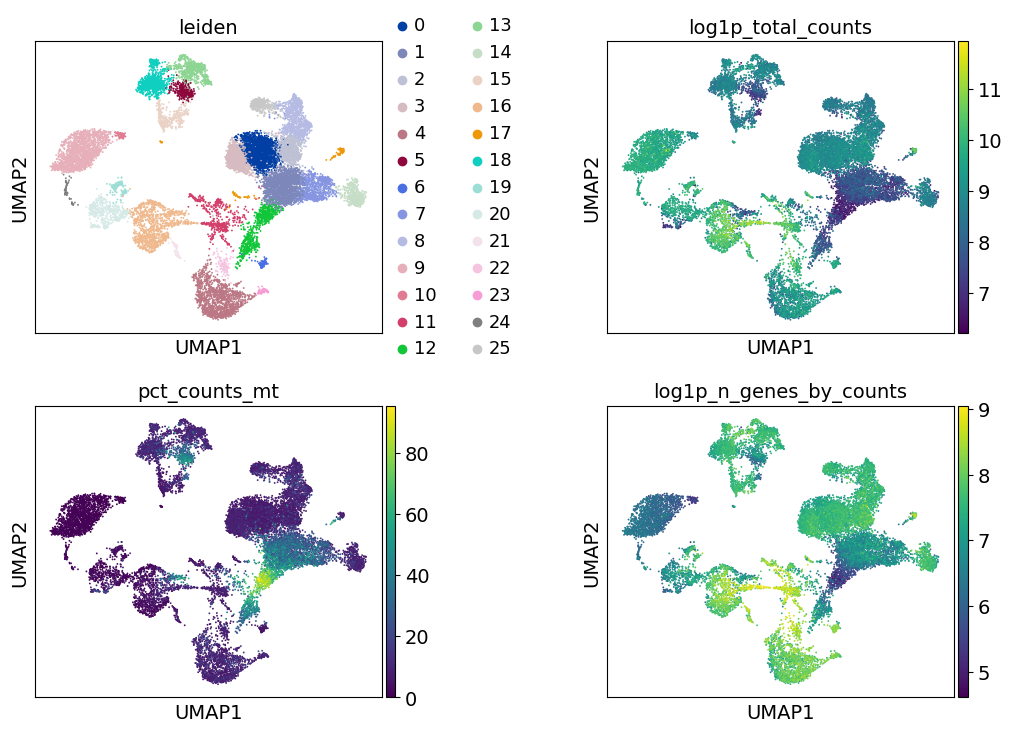

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

# **Manual Cell Type Annotation**

In [ ]:
for res in [0.02, 0.5, 2.0]:
    sc.tl.leiden(adata, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph")

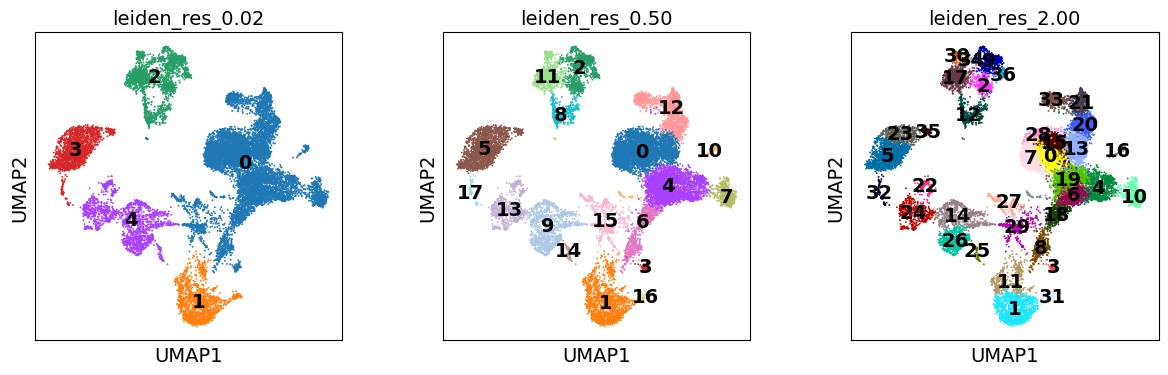

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_2.00"],
    legend_loc="on data",
)

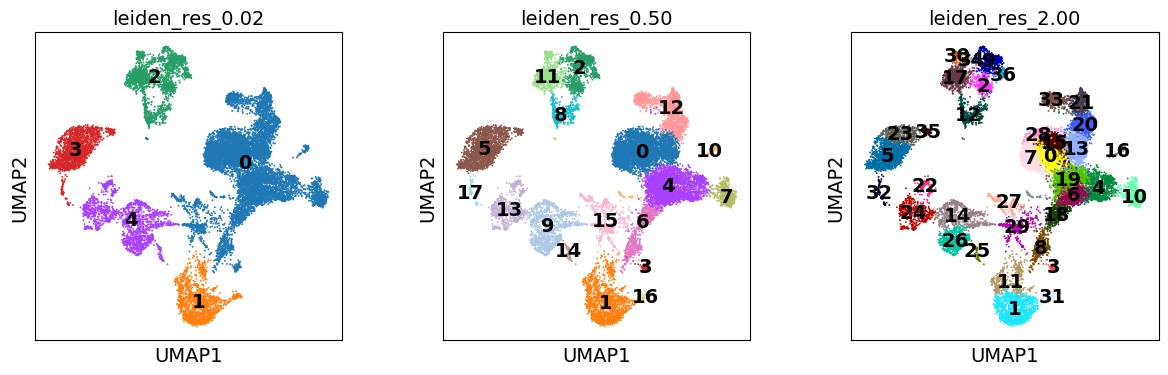

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_2.00"],
    legend_loc="on data",
)

# **Marker Gene Set**

In [ ]:
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    # Note: DMXL2 should be negative
    "cDC2": ["CST3", "COTL1", "LYZ", "DMXL2", "CLEC10A", "FCER1A"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    # Note HBM and GYPA are negative markers
    "Proerythroblast": ["CDK6", "SYNGR1", "HBM", "GYPA"],
    "NK": ["GNLY", "NKG7", "CD247", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNE1"],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    # Note IGHD and IGHM are negative markers
    "B cells": [
        "MS4A1",
        "ITGB1",
        "COL4A4",
        "PRDM1",
        "IRF4",
        "PAX5",
        "BCL11A",
        "BLK",
        "IGHD",
        "IGHM",
    ],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    # Note PAX5 is a negative marker
    "Plasmablast": ["XBP1", "PRDM1", "PAX5"],
    "CD4+ T": ["CD4", "IL7R", "TRBC2"],
    "CD8+ T": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"],
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
}

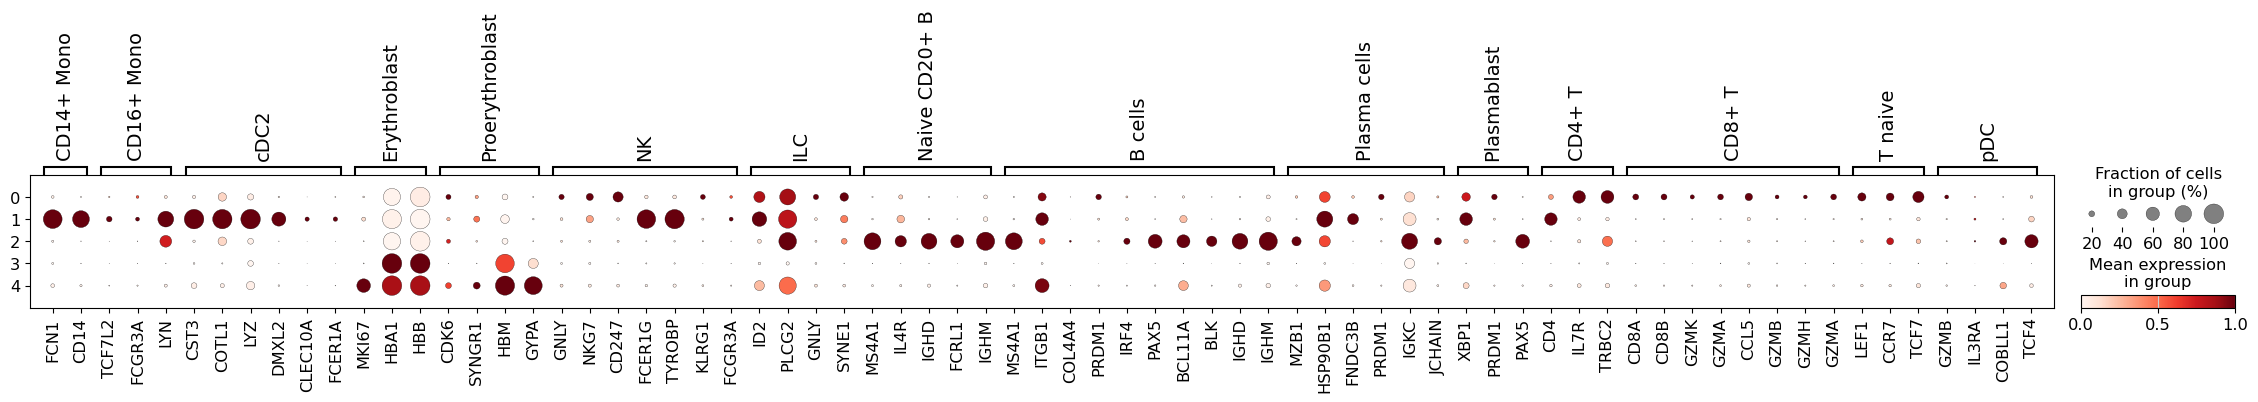

In [ ]:
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.02", standard_scale="var")

In [ ]:
adata.obs["cell_type_lvl1"] = adata.obs["leiden_res_0.02"].map(
    {
        "0": "Lymphocytes",
        "1": "Monocytes",
        "2": "Erythroid",
        "3": "B Cells",
    }
)

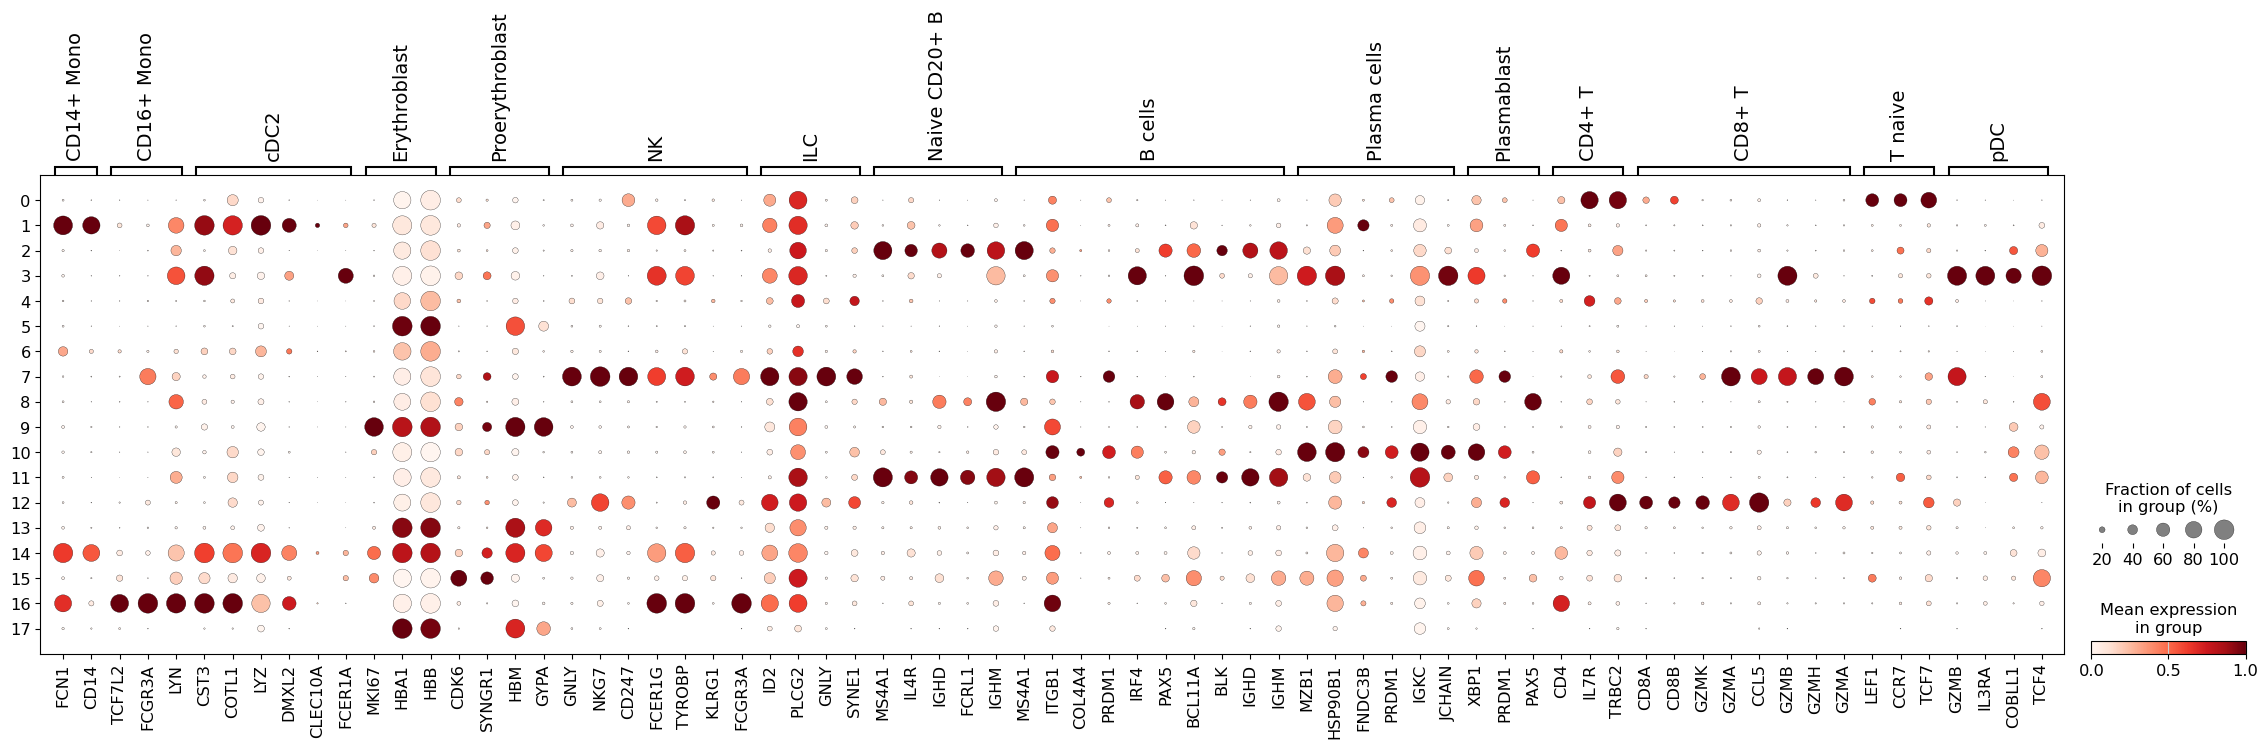

In [ ]:
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.50", standard_scale="var")

# **Differentially-expressed Genes as Markers**


In [ ]:
# Obtain cluster-specific differentially expressed genes
sc.tl.rank_genes_groups(adata, groupby="leiden_res_0.50", method="wilcoxon")

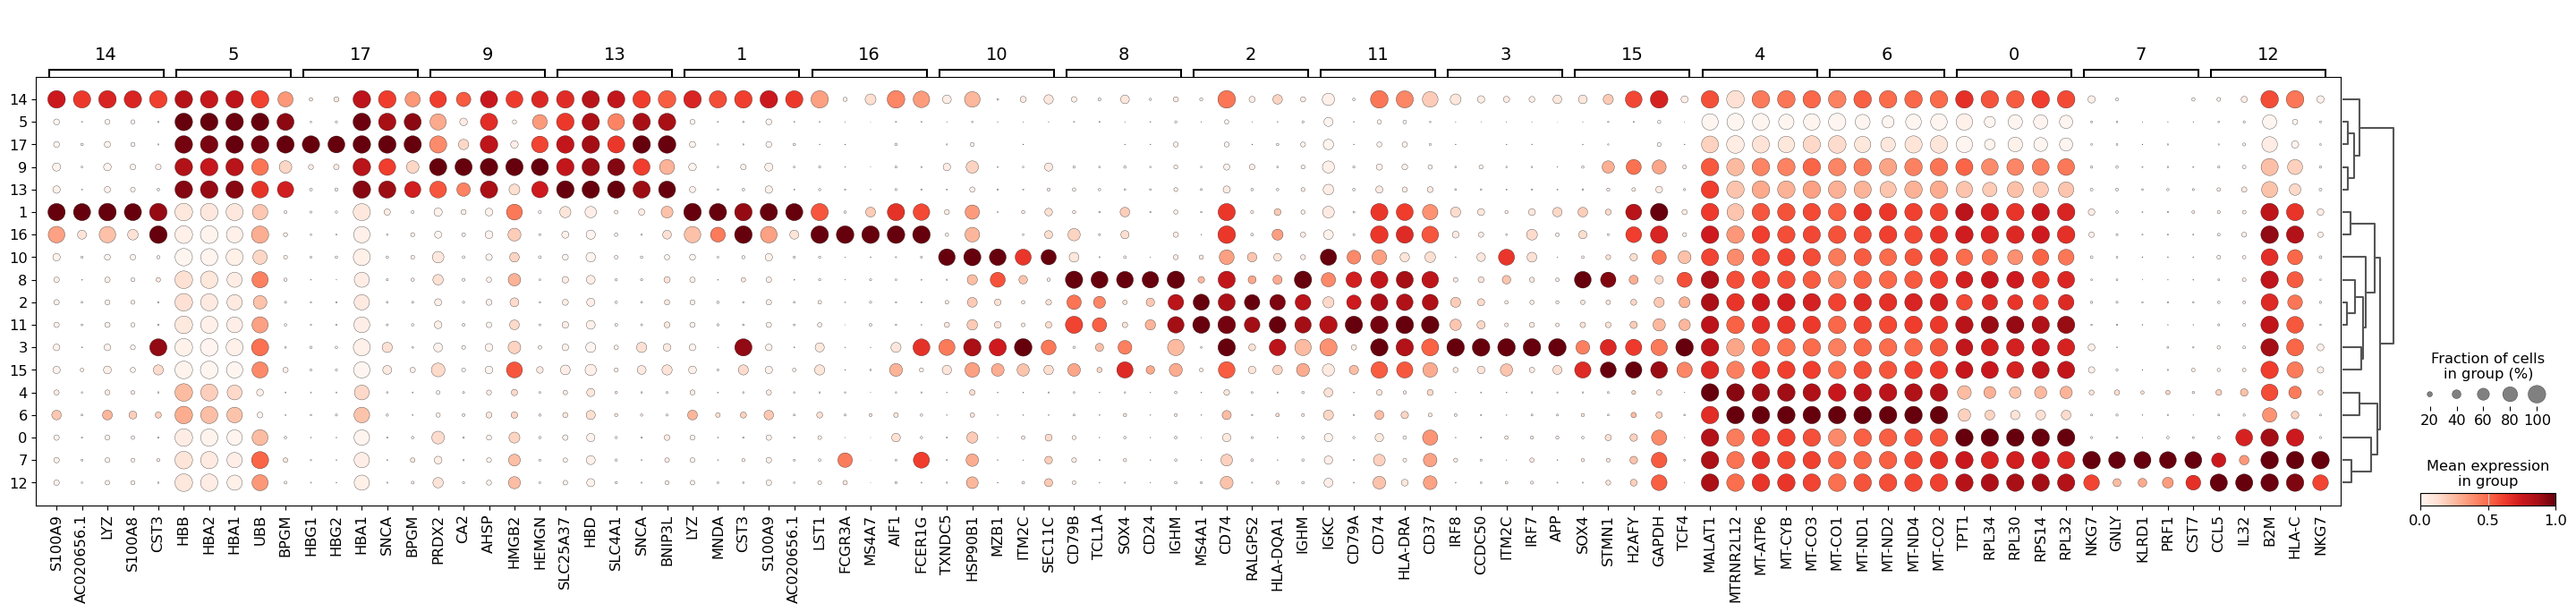

In [ ]:
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden_res_0.50", standard_scale="var", n_genes=5)

In [ ]:
sc.get.rank_genes_groups_df(adata, group="7").head(5)

,names,scores,logfoldchanges,pvals,pvals_adj
0,NKG7,35.537918,6.548978,1.277051e-276,2.991748e-272
1,GNLY,33.851448,7.374753,3.455431e-251,4.047519e-247
2,KLRD1,33.814442,5.832656,1.209767e-250,9.447073e-247
3,PRF1,33.023769,5.431675,3.703158e-239,2.168847e-235
4,CST7,33.007786,5.233107,6.280117e-239,2.942486e-235


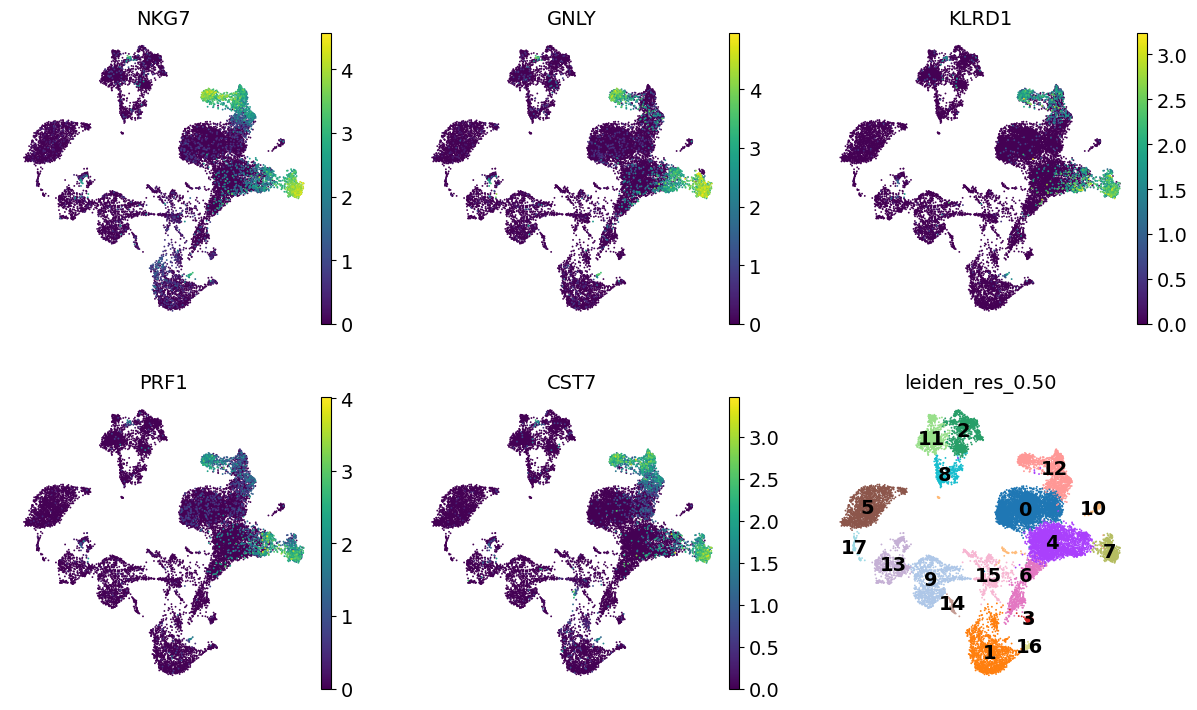

In [ ]:
dc_cluster_genes = sc.get.rank_genes_groups_df(adata, group="7").head(5)["names"]
sc.pl.umap(
    adata,
    color=[*dc_cluster_genes, "leiden_res_0.50"],
    legend_loc="on data",
    frameon=False,
    ncols=3,
)

# **Cell 1: Import Tools and Define Settings**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42
LABEL_COLUMN = "cell_type_lvl1"
POSITIVE_LABEL = "B Cells"
N_GENES = 500
N_JOBS = 2

# **Cell 2: Prepare Expression Data and Split Cells**

In [ ]:
if LABEL_COLUMN not in adata.obs:
    raise ValueError("Run the tutorial's cell-type annotation cell first.")

if "counts" not in adata.layers:
    raise ValueError("The tutorial's saved counts layer is missing.")

# Exclude cells with missing annotations.
keep = adata.obs[LABEL_COLUMN].notna().to_numpy()
labels = adata.obs.loc[keep, LABEL_COLUMN].astype(str)

if POSITIVE_LABEL not in labels.unique():
    raise ValueError(
        f"{POSITIVE_LABEL!r} was not found. "
        f"Available labels: {sorted(labels.unique())}"
    )

y = (labels == POSITIVE_LABEL).to_numpy(dtype=int)
cell_indices = np.flatnonzero(keep)

# Copy the saved counts into a separate sparse matrix.
X = sparse.csr_matrix(
    adata.layers["counts"][keep], dtype=np.float64
).copy()

if not np.isfinite(X.data).all() or (X.data < 0).any():
    raise ValueError("Expected finite, nonnegative counts.")

if np.any(np.asarray(X.sum(axis=1)).ravel() == 0):
    raise ValueError("Found cells with zero total counts.")

# Each cell is transformed independently using a fixed target.
X = normalize(X, norm="l1", axis=1) * 10_000
X.data = np.log1p(X.data)
X = X.tocsr()

# Reserve 20% for testing.
indices = np.arange(len(y))
trainval_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

# Reserve 25% of the remaining 80% for validation.
train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.25,
    stratify=y[trainval_idx],
    random_state=SEED,
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

if np.bincount(y_train, minlength=2).min() < 5:
    raise ValueError(
        "Five-fold CV requires at least five training cells per class."
    )

summary = pd.DataFrame([
    {
        "Partition": name,
        "Cells": len(target),
        "B Cells": int(target.sum()),
        "Other cells": int((target == 0).sum()),
        "B-cell fraction": target.mean(),
    }
    for name, target in [
        ("Training", y_train),
        ("Validation", y_val),
        ("Test", y_test),
    ]
])

display(summary.round(3))
print("Positive class: B Cells (1)")
print("Negative class: other annotated cells (0)")
print("Expression matrix:", X.shape)

,Partition,Cells,B Cells,Other cells,B-cell fraction
0,Training,9178,1055,8123,0.115
1,Validation,3060,352,2708,0.115
2,Test,3060,352,2708,0.115


Positive class: B Cells (1)
Negative class: other annotated cells (0)
Expression matrix: (15298, 23427)


***Cell 3: Define Pipelines and Search Grids***

In [ ]:
def make_classifier_pipeline(classifier, scale=False):
    steps = [
        ("remove_constant", VarianceThreshold()),
        ("select_genes", SelectKBest(score_func=f_classif, k=N_GENES)),
    ]

    if scale:
        steps.append(("scale", StandardScaler(with_mean=False)))

    steps.append(("classifier", classifier))
    return Pipeline(steps)


model_specs = {
    "Logistic regression": (
        make_classifier_pipeline(
            LogisticRegression(
                solver="liblinear",
                max_iter=5000,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.01, 0.1, 1.0],
        },
    ),

    "Random forest": (
        make_classifier_pipeline(
            RandomForestClassifier(
                n_estimators=200,
                random_state=SEED,
                n_jobs=1,
            )
        ),
        {
            "classifier__max_depth": [10, None],
            "classifier__min_samples_leaf": [1, 5],
        },
    ),

    "RBF SVM": (
        make_classifier_pipeline(
            SVC(
                kernel="rbf",
                probability=False,
                cache_size=300,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.1, 1.0],
            "classifier__gamma": ["scale", 0.001],
        },
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

# **Cell 4: Run Five-fold Grid Search and Choose the Classifier**

In [ ]:
def positive_scores(model, features):
    """Return continuous scores for positive class 1."""
    if hasattr(model, "predict_proba"):
        positive_column = np.flatnonzero(model.classes_ == 1)[0]
        return model.predict_proba(features)[:, positive_column]

    if not np.array_equal(model.classes_, np.array([0, 1])):
        raise ValueError("Expected binary classes [0, 1].")

    return model.decision_function(features)


searches = {}
validation_scores = {}
comparison_rows = []

for name, (pipeline, grid) in model_specs.items():
    print(f"\nRunning five-fold grid search: {name}")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=N_JOBS,
        pre_dispatch=N_JOBS,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )

    # Only training data enter grid search.
    search.fit(X_train, y_train)
    searches[name] = search

    scores = positive_scores(search.best_estimator_, X_val)
    validation_scores[name] = scores

    comparison_rows.append({
        "Classifier": name,
        "CV average precision": search.best_score_,
        "CV AP SD": search.cv_results_["std_test_score"][search.best_index_],
        "Validation average precision": average_precision_score(y_val, scores),
        "Validation ROC-AUC": roc_auc_score(y_val, scores),
        "Best parameters": search.best_params_,
    })

comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Classifier")
    .sort_values(
        "Validation average precision",
        ascending=False,
        kind="stable",
    )
)

display(comparison.round(4))

winner_name = comparison.index[0]
winner_model = searches[winner_name].best_estimator_

print(f"\nSelected classifier: {winner_name}")
print("Selection criterion: highest validation average precision")
print("The test set has not been used for model selection.")


Running five-fold grid search: Logistic regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Running five-fold grid search: Random forest
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Running five-fold grid search: RBF SVM
Fitting 5 folds for each of 4 candidates, totalling 20 fits


,CV average precision,CV AP SD,Validation average precision,Validation ROC-AUC,Best parameters
Classifier,,,,,
Logistic regression,1.0,0.0,1.0,1.0,{'classifier__C': 0.01}
Random forest,1.0,0.0,1.0,1.0,"{'classifier__max_depth': 10, 'classifier__min..."
RBF SVM,1.0,0.0,1.0,1.0,"{'classifier__C': 0.1, 'classifier__gamma': 's..."



Selected classifier: Logistic regression
Selection criterion: highest validation average precision
The test set has not been used for model selection.


# **Cell 5: Compare Validation ROC curves**

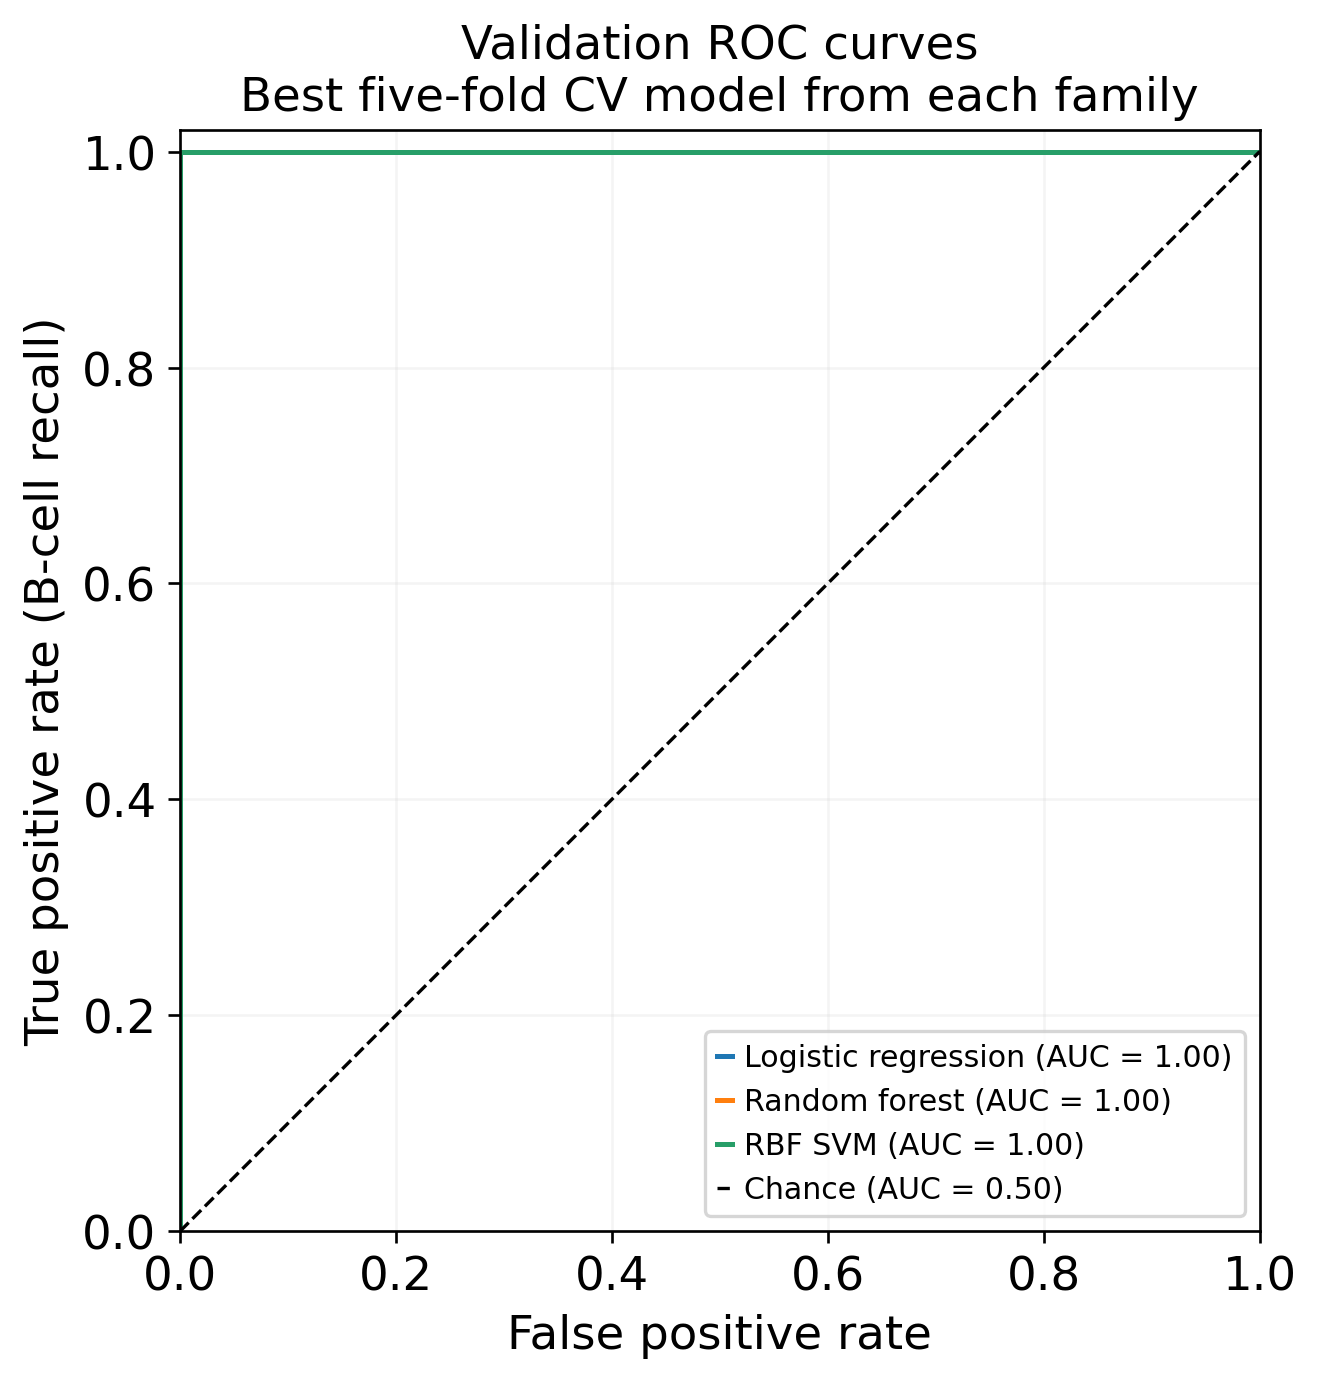

Winner by validation average precision: Logistic regression
ROC-AUC is displayed for comparison; it did not choose the winner.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 6), dpi=120)

for name, scores in validation_scores.items():
    RocCurveDisplay.from_predictions(
        y_val,
        scores,
        name=name,
        ax=ax,
    )

ax.plot(
    [0, 1], [0, 1],
    "k--",
    linewidth=1,
    label="Chance (AUC = 0.50)",
)
ax.set(
    title="Validation ROC curves\nBest five-fold CV model from each family",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    f"Winner by validation average precision: {winner_name}\n"
    "ROC-AUC is displayed for comparison; it did not choose the winner."
)

# **Cell 6: Evaluate the Winner on Test Set**

Final test evaluation: Logistic regression
Test average precision: 1.0000
Test ROC-AUC:           1.0000
Test B-cell prevalence: 0.1150

Classification report at the model's default threshold:

                       precision    recall  f1-score   support

Other annotated cells      1.000     1.000     1.000      2708
              B Cells      1.000     1.000     1.000       352

             accuracy                          1.000      3060
            macro avg      1.000     1.000     1.000      3060
         weighted avg      1.000     1.000     1.000      3060



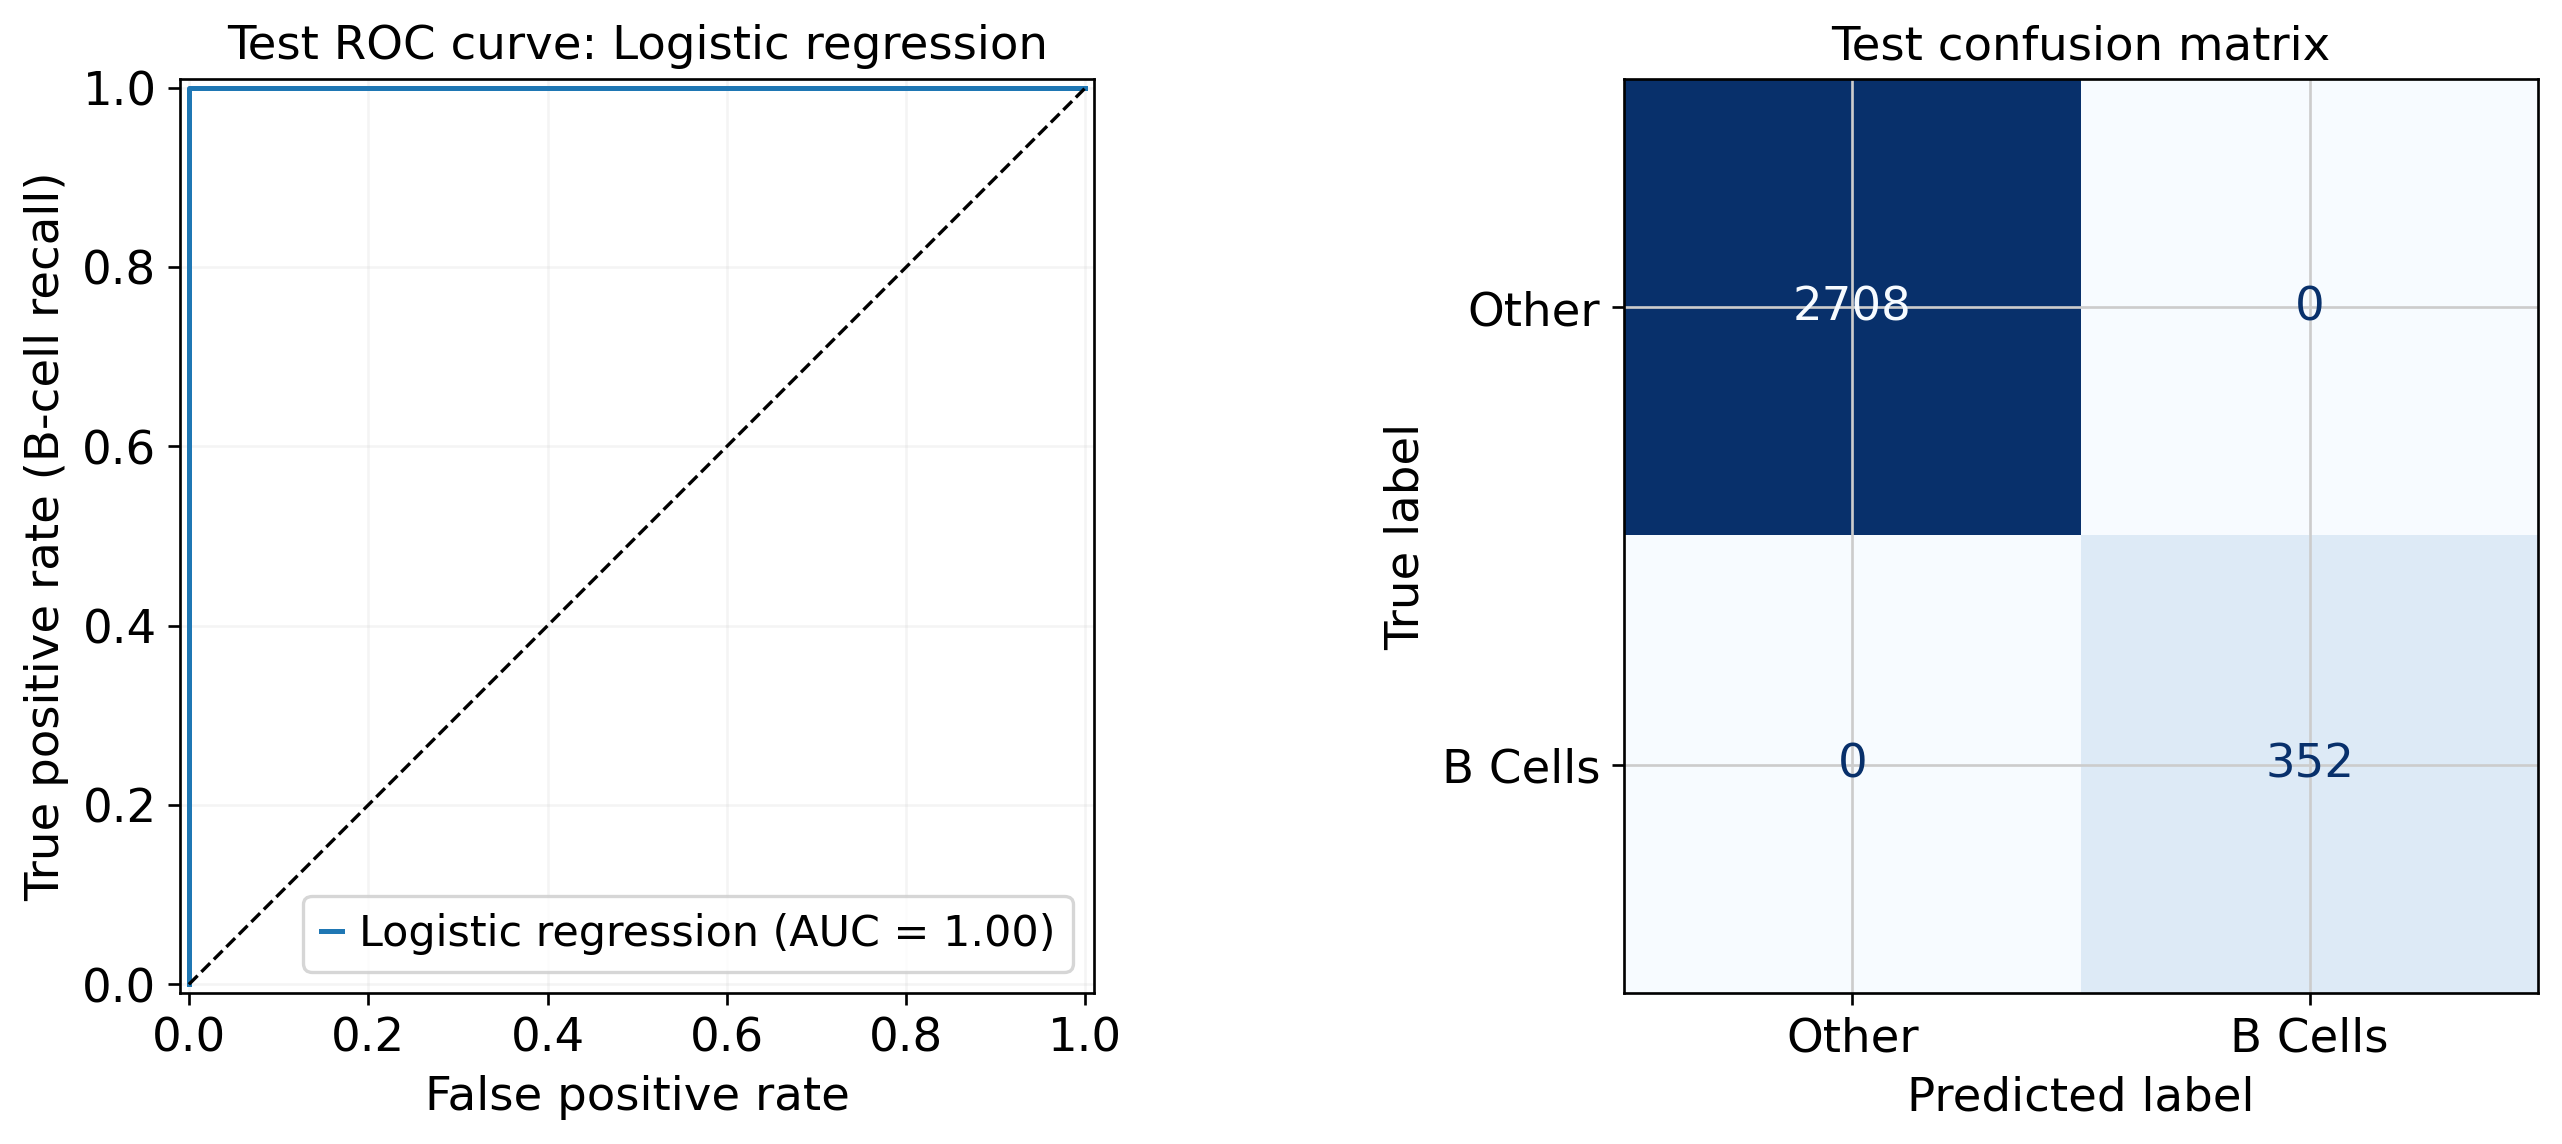

,cell_id,reference_label,predicted_label,positive_class_score,correct
0,GAAGCGAAGTCATCCA-1,0,0,0.000162,True
1,TAAGCACGTATCATGC-1,0,0,0.000047,True
2,TGAATCGAGTCGCCAC-1,0,0,0.000055,True
3,TTTACTGCAAGGGTCA-1,1,1,0.998719,True
4,ATACTTCAGCGTGAGT-1,0,0,0.000043,True


In [ ]:
test_scores = positive_scores(winner_model, X_test)
test_predictions = winner_model.predict(X_test)

test_ap = average_precision_score(y_test, test_scores)
test_auc = roc_auc_score(y_test, test_scores)

print(f"Final test evaluation: {winner_name}")
print(f"Test average precision: {test_ap:.4f}")
print(f"Test ROC-AUC:           {test_auc:.4f}")
print(f"Test B-cell prevalence: {y_test.mean():.4f}")
print("\nClassification report at the model's default threshold:\n")

print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Other annotated cells", "B Cells"],
    digits=3,
    zero_division=0,
))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)

RocCurveDisplay.from_predictions(
    y_test,
    test_scores,
    name=winner_name,
    ax=axes[0],
)
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(
    title=f"Test ROC curve: {winner_name}",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
)
axes[0].grid(alpha=0.2)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Other", "B Cells"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[1],
)
axes[1].set_title("Test confusion matrix")

plt.tight_layout()
plt.show()

test_results = pd.DataFrame({
    "cell_id": adata.obs_names[cell_indices[test_idx]].to_numpy(),
    "reference_label": y_test,
    "predicted_label": test_predictions,
    "positive_class_score": test_scores,
})
test_results["correct"] = (
    test_results["reference_label"] == test_results["predicted_label"]
)

display(test_results.head())

## Exit questions

### 1. Define the classification problem
What are the observations, predictor features, and target labels in this classification problem?

**Your response:** The observations are individual cells, and the predictor features are the gene expression measurements for each cell. The target labels are whether a cell is a B cell (1) or another annotated cell type (0). The model uses gene expression patterns to predict which category each cell belongs to.

### 2. Establish a baseline
Using the training partition, calculate the accuracy of a classifier that predicts "Other" for every cell. What would its B-cell recall be? Why stratify the split?

**Your response:** A classifier that predicts "Other" for every cell would have an accuracy of 8,123/9,178 = 88.5%. However, its B-cell recall would be 0% because it would fail to identify any actual B cells. Stratifying the split makes sure that the training, validation, and test sets have similar proportions of B cells and other cells, which makes the comparisons more reliable.

### 3. Identify the selected model
Which classifier was selected, and what were its best hyperparameters?

**Your response:** Logistic regression was selected as the best classifier, with a C value of 0.01. All three classifiers achieved a validation average precision of 1.0, so logistic regression was selected because it came first in the model comparison order when the scores were tied.

### 4. Interpret what the classifier learned
What did the classifier learn to predict? How does this differ from independently establishing a cell's biological identity?

**Your response:** The classifier learned to recognize gene expression patterns associated with cells labeled as B cells and use those patterns to predict whether other cells belong to the same group. However, this does not independently prove that a cell is biologically a B cell because the model is learning from labels that were already assigned. Confirming the biological identity would require additional evidence, such as checking known B-cell markers or using an independent experimental method.

### 5. Interpret classification errors
What would a false positive and a false negative mean in this analysis?

**Your response:** A false positive would occur if the model predicted that a cell was a B cell when it was actually labeled as another cell type. A false negative would occur if the model predicted that a B cell was another cell type. In my results, there were no false positives or false negatives.

### 6. Evaluate the classifier
Is the selected classifier a good classifier for this task? Justify your answer using its test-set sensitivity, precision, specificity, and F1 score. Calculate specificity from the confusion matrix as TN / (TN + FP).

**Your response:** Yes, logistic regression performed well on this classification task. The test-set sensitivity and precision were both 100%, meaning the model correctly identified all 352 B cells without incorrectly labeling any other cells as B cells. Specificity was 2,708/(2,708 + 0) = 1.00, or 100%, meaning all other cells were correctly classified. The F1 score was also 1.00, showing excellent precision and recall. However, these results only show how well the model performed on this dataset and its existing labels.

### 7. Assess independence and leakage
The classifier's gene selection, scaling, and hyperparameter tuning use only training data. However, the tutorial generated the cell-type labels by clustering and annotating the full dataset before the split.

Is the test set fully independent of the complete analysis? Explain how test cells influenced the upstream analysis, what this means for interpreting high test accuracy, and what a stronger evaluation would require.

**Your response:** No, the test set is not fully independent because the original cell-type labels were created by clustering and annotating the entire dataset before splitting it. This means the test cells influenced the clustering patterns used to assign their labels, even though they were not used to train the classifier directly. Because of this, the 100% test accuracy may overestimate how well the model would perform on completely new cells. A stronger evaluation would use a separate dataset with independently assigned cell-type labels to test whether the classifier can accurately identify B cells in new samples.